#### <font color=skyblue>Exercise: Normal mixture</font> ####

Solve the multivariate normal mixture model using the maximum likelihood estimation (MLE) method. The model is defined as follows:

Objective function:

$$L(\Omega) = \sum_{i=1}^n \ln(\pi_1 N(x_i|\mu_1, \sigma^2_1) + \pi_2 N(x_i|\mu_2, \sigma^2_2))$$

The optimization problem becomes

$\displaystyle \max_{\Omega = \{\pi_1, \pi_2, \mu_1, \sigma_1, \mu_2, \sigma_2|\pi_1 + \pi_2 =1, 0 \leq \pi_1 \leq 1, \pi_2 \leq 1, \sigma_1 > 0, \sigma_2 >0\}} L(\Omega)$

Note: for normal mixture, you may use GaussianMixture from sklearn.mixture to fit the model.

<font color="yellow" face="Arial" size="4">1. Observe some mixture of normal distributions as shown below. </font>

<img src = pictures/normal_mixture.png width=800>

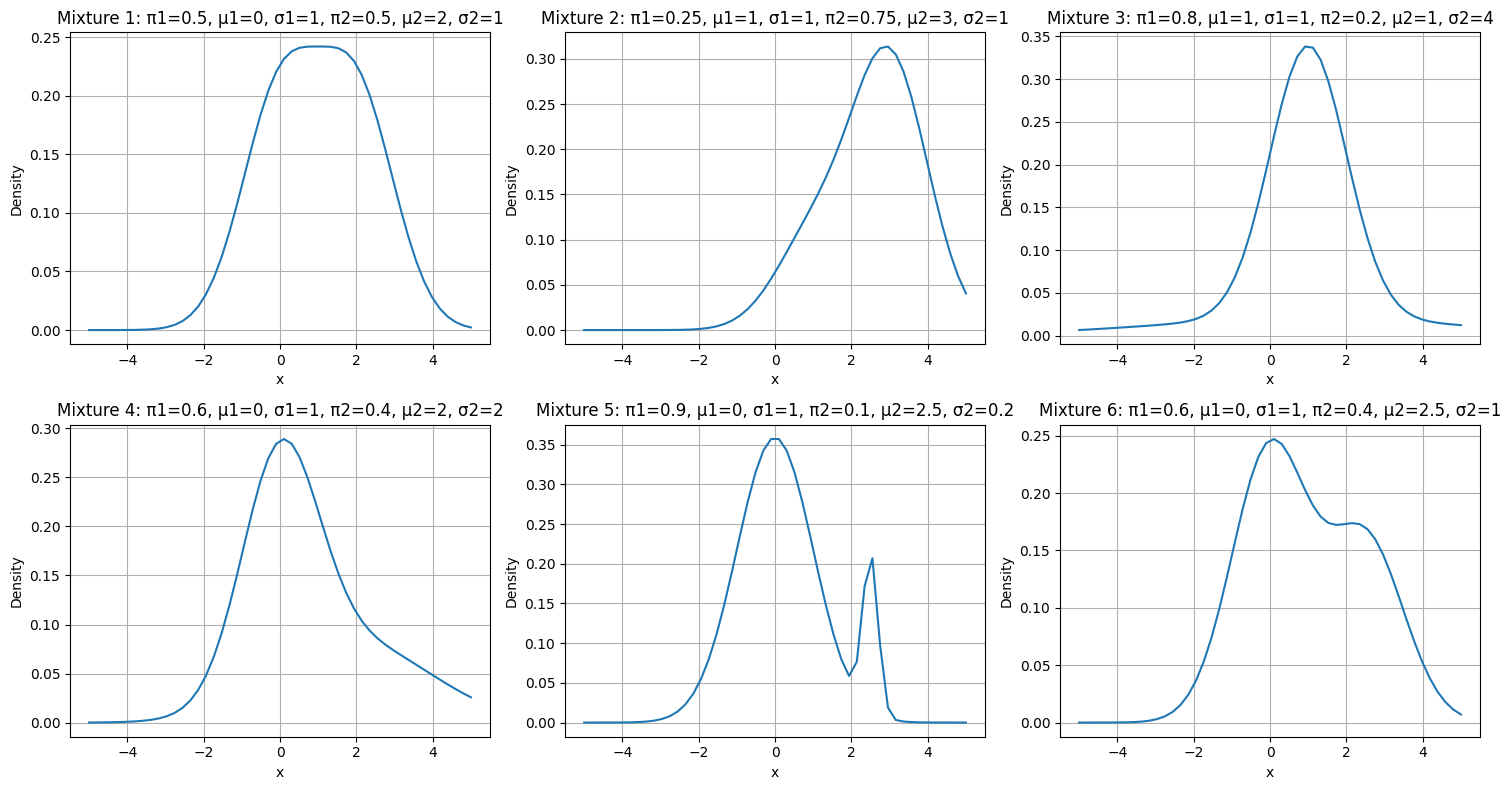

In [7]:
# plot 6 normal mixture with different parameters in a 2x3 grid
import matplotlib.pyplot as plt
from scipy.stats import norm
import numpy as np

# Define the parameters for the 6 normal mixtures
parameters = [
    (0.5, 0, 1, 0.5, 2, 1),
    (0.25, 1, 1, 0.75, 3, 1),
    (0.8, 1, 1, 0.2, 1, 4),
    (0.6, 0, 1, 0.4, 2, 2),
    (0.9, 0, 1, 0.1, 2.5, 0.2),
    (0.6, 0, 1, 0.4, 2.5, 1)
]

# Create a figure with a 2x3 grid of subplots
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

# Plot each normal mixture
for i in range(6):
    pi1 = parameters[i][0]
    mu1 = parameters[i][1]
    sigma1 = parameters[i][2]
    pi2 = parameters[i][3]
    mu2 = parameters[i][4]
    sigma2 = parameters[i][5]

    x = np.linspace(-5, 5)
    y = pi1 * norm.pdf(x, mu1, sigma1) + pi2 * norm.pdf(x, mu2, sigma2)
    axes[i].plot(x,
                y)
    axes[i].set_xlabel('x')
    axes[i].set_ylabel('Density')
    axes[i].set_title(f'Mixture {i+1}: π1={pi1}, μ1={mu1}, σ1={sigma1}, π2={pi2}, μ2={mu2}, σ2={sigma2}')
    axes[i].grid()

plt.tight_layout()
plt.show()


<font color="yellow" face="Arial" size="4">2. Define necessary definitions for the objective function.</font>

In [8]:
# define a function to generate random samples from the mixture distribution
def generate_samples(parameters, n_samples):
    pi1 = parameters[0]
    mu1 = parameters[1]
    sigma1 = parameters[2]
    pi2 = parameters[3]
    mu2 = parameters[4]
    sigma2 = parameters[5]

    # generate random samples from the mixture distribution, avoid using loop for efficiency
    u = np.random.rand(n_samples)
    samples = np.where(u < pi1, np.random.normal(mu1, sigma1, n_samples), np.random.normal(mu2, sigma2, n_samples))
    return np.array(samples)


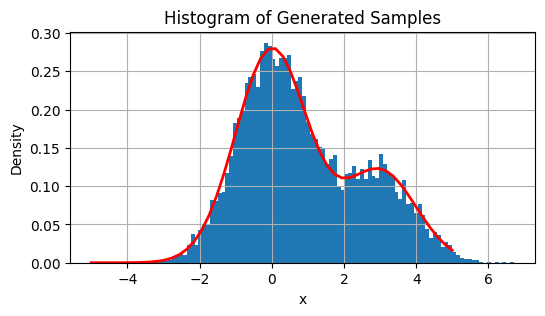

In [28]:
# given the parameters of the mixture distribution, generate 1000 samples and plot the histogram
n_samples = 10000
parameters = (0.7, 0, 1, 0.3, 3, 1)
samples = generate_samples(parameters, n_samples)

fig = plt.figure(figsize=(6, 3))
plt.hist(samples, bins=100, density=True)
# plot the true density function of the mixture distribution
x = np.linspace(-5, 5)
y = parameters[0] * norm.pdf(x, parameters[1], parameters[2]) + parameters[3] * norm.pdf(x, parameters[4], parameters[5])
plt.plot(x, y, 'r-', linewidth=2)
plt.xlabel('x')
plt.ylabel('Density')
plt.title('Histogram of Generated Samples')
plt.grid()
plt.show()

<font color="yellow" face="Arial" size="4">3. Use the GaussianMixture class from sklearn.mixture to fit a mixture of two normal distributions to the data. </font>

In [29]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))

# use GaussianMixture from sklearn.mixture to fit the model and estimate the parameters
from sklearn.mixture import GaussianMixture

# create a GaussianMixture object with 2 components
gmm = GaussianMixture(n_components=2, verbose=0)

# fit the model to the data
gmm.fit(samples.reshape(-1, 1))

# print the estimated parameters
print("Estimated parameters:")
print("pi1:", gmm.weights_[0])
print("mu1:", gmm.means_[0, 0])
print("sigma1:", np.sqrt(gmm.covariances_[0, 0]))
print("pi2:", gmm.weights_[1])
print("mu2:", gmm.means_[1, 0])
print("sigma2:", np.sqrt(gmm.covariances_[1, 0]))

Estimated parameters:
pi1: 0.6690238789108384
mu1: -0.04701142365158724
sigma1: [0.95928491]
pi2: 0.33097612108916147
mu2: 2.8130722708919915
sigma2: [1.08411719]


<font color="yellow" face="Arial" size="4">4. Plot the results of the fitted model for various sample sizes.</font>

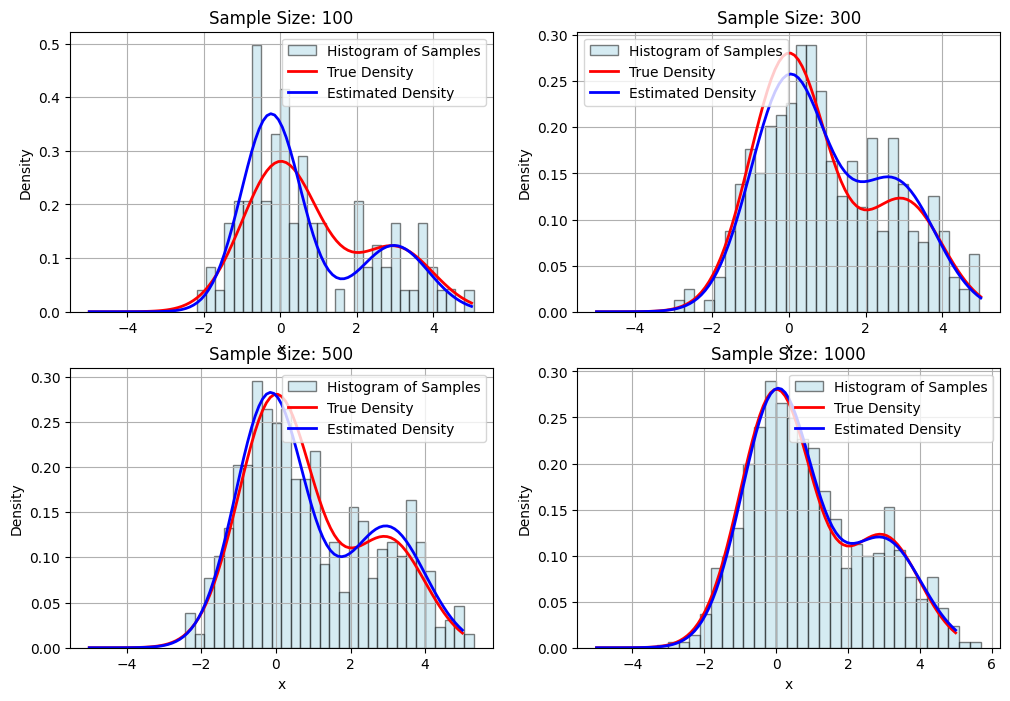

n,π1,μ1,σ1,π2,μ2,σ2
100,0.720300,-0.244200,0.778500,0.279700,2.972900,0.902700
300,0.631200,0.007600,0.995100,0.368800,2.767700,1.054400
500,0.653700,-0.152700,0.927500,0.346300,2.972100,1.032300
1000,0.691800,0.040500,0.987700,0.308200,2.993200,1.055600


In [31]:
# draw the histogram of the samples and the estimated density function and the true density function of the mixture distribution
# based on four sample sizes: 100, 300, 500, 1000
import pandas as pd

sample_sizes = [100, 300, 500, 1000]

# plot in a 2x2 grid
estimated_results = []
fig = plt.figure(figsize=(12, 8))
for n in sample_sizes:
    # generate samples
    samples = generate_samples(parameters, n)
    
    # fit the GMM
    gmm = GaussianMixture(n_components=2, verbose=0)
    gmm.fit(samples.reshape(-1, 1))
    order = np.argsort(gmm.means_[:, 0])
    estimated_results.append({
        'Sample Size': n,
        'pi1': float(gmm.weights_[order[0]]),
        'mu1': float(gmm.means_[order[0], 0]),
        'sigma1': float(np.sqrt(gmm.covariances_[order[0], 0, 0])),
        'pi2': float(gmm.weights_[order[1]]),
        'mu2': float(gmm.means_[order[1], 0]),
        'sigma2': float(np.sqrt(gmm.covariances_[order[1], 0, 0])),
    })

    # plot the histogram of the samples
    plt.subplot(2, 2, sample_sizes.index(n) + 1)
    plt.hist(samples, bins=30, density=True, alpha=0.5, \
             label='Histogram of Samples', edgecolor='black', color='lightblue')
    # plot the true density function
    x = np.linspace(-5, 5,100)
    y_true = parameters[0] * norm.pdf(x, parameters[1], parameters[2]) + parameters[3] * norm.pdf(x, parameters[4], parameters[5])
    plt.plot(x, y_true, 'r-', linewidth=2, label='True Density')
    # plot the estimated density function
    y_est = gmm.weights_[0] * norm.pdf(x, gmm.means_[0, 0], np.sqrt(gmm.covariances_[0, 0])) + gmm.weights_[1] * norm.pdf(x, gmm.means_[1, 0], np.sqrt(gmm.covariances_[1, 0]))
    plt.plot(x, y_est, 'b-', linewidth=2, label='Estimated Density')
    plt.title(f'Sample Size: {n}')
    plt.xlabel('x')
    plt.ylabel('Density')
    plt.legend()
    plt.grid()

plt.show()
results_table = pd.DataFrame(estimated_results).round(4).rename(columns={
    'Sample Size': 'n',
    'pi1': 'π1', 'mu1': 'μ1', 'sigma1': 'σ1',
    'pi2': 'π2', 'mu2': 'μ2', 'sigma2': 'σ2',
})
display(
    results_table.style
    .hide(axis='index')
    .set_table_attributes('style="width:100%; table-layout:fixed;"')
    .set_properties(**{'text-align': 'center', 'font-size': '12px', 'padding': '4px 6px'})
)



<font color="yellow" face="Arial" size="4">5. Table of results for different sample sizes. </font>

<font color="yellow" face="Arial" size="4">6. Analysis of the results: the consistency of the estimates with increasing sample size. </font>

用 Monte Carlo 驗證

$$P\bigl( \|\hat{\theta}_n-\theta_0\|>\varepsilon \bigr) \to 0$$

這比只看 bias 或 variance 更接近 consistency 的數學定義。對於多維參數 ，可以直接畫

$$\|\hat{\theta}_n-\theta_0\|​$$

<font color="yellow" face="Arial" size="4">7. (optional) Analysis of the results: the asymptotic efficiency of the estimates with increasing sample size. </font>

$$Var(\hat{\theta}_{MLE}) \approx \frac{1}{n} I(\theta_0)^{-1}$$

<font color="yellow" face="Arial" size="4">8. Conclusion and future work. </font>